In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

def generate_2d_order_dag(N, box_size=1.0):
    """
    Generates a DAG using a 2D order by randomly placing N points in (x, t) space
    and enforcing a causal structure where t_i < t_j.
    
    Parameters:
        N (int): Number of nodes
        box_size (float): Size of the spatial coordinate domain (default 1.0)
    
    Returns:
        G (networkx.DiGraph): A DAG with edges respecting the causal order
    """
    # Step 1: Randomly generate (x, t) coordinates
    x = np.random.uniform(0, box_size, N)  # Spatial coordinate
    t = np.random.uniform(0, box_size, N)  # Temporal coordinate

    # Step 2: Sort nodes by increasing time t
    indices = np.argsort(t)
    sorted_x = x[indices]
    sorted_t = t[indices]

    # Step 3: Create a DAG using causal precedence
    G = nx.DiGraph()
    for i in range(N):
        G.add_node(i, pos=(sorted_x[i], sorted_t[i]))  # Store node positions
        for j in range(i + 1, N):
            if sorted_t[i] < sorted_t[j]:  # Ensure acyclicity
                G.add_edge(i, j)

    return G

def plot_dag(G):
    """
    Plots the DAG using its 2D embedding.
    """
    pos = nx.get_node_attributes(G, 'pos')
    plt.figure(figsize=(8, 6))
    nx.draw(G, pos, with_labels=True, node_size=500, node_color='skyblue', edge_color='gray', arrows=True)
    plt.xlabel("Spatial coordinate (x)")
    plt.ylabel("Temporal coordinate (t)")
    plt.title("DAG Generated from 2D Order")
    plt.show()


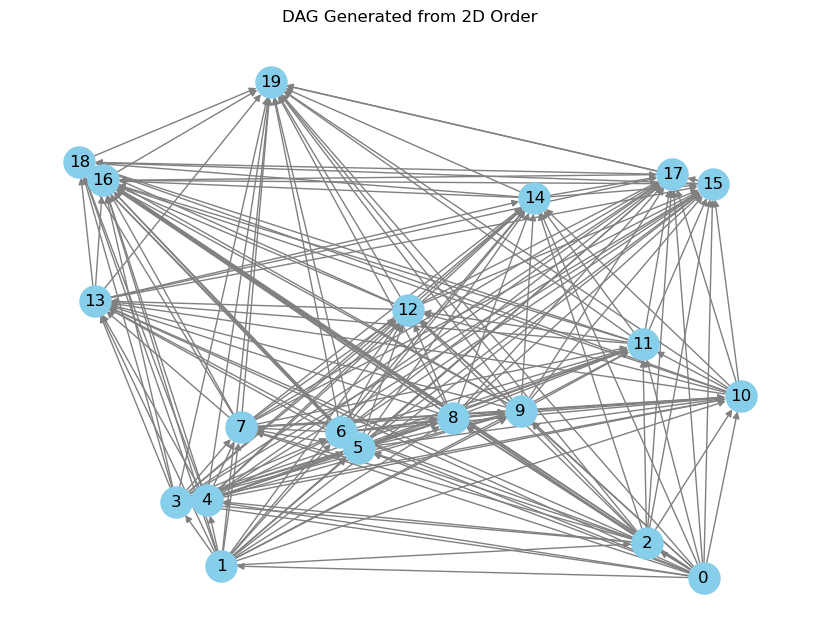

In [6]:
# Example usage:
N = 20  # Number of nodes
dag = generate_2d_order_dag(N)
plot_dag(dag)

In [35]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from itertools import combinations

def generate_2d_order_dag_with_transitive_closure(N, box_size=1.0):
    """
    Generates a DAG using a 2D order, adds transitive closure, and counts 3-chains and diamonds.

    Parameters:
        N (int): Number of nodes
        box_size (float): Size of the spatial coordinate domain

    Returns:
        G (networkx.DiGraph): The generated DAG with transitive closure
        counts (dict): Counts of 3-chains and diamonds
    """
    # Step 1: Generate random (x, t) coordinates
    x = np.random.uniform(0, box_size, N)  # Spatial coordinate
    t = np.random.uniform(0, box_size, N)  # Temporal coordinate

    # Step 2: Sort nodes by increasing time t
    indices = np.argsort(t)
    sorted_x = x[indices]
    sorted_t = t[indices]

    # Step 3: Create a DAG using 2D order
    G = nx.DiGraph()
    for i in range(N):
        G.add_node(i, pos=(sorted_x[i], sorted_t[i]))
        for j in range(i + 1, N):
            if sorted_t[i] < sorted_t[j]:  # Enforce acyclicity
                G.add_edge(i, j)

    # Step 4: Compute transitive closure
    G_tc = nx.transitive_closure(G)

    # Step 5: Count 3-chains and diamonds
    num_3chains = 0
    num_diamonds = 0

    for i in G_tc.nodes:
        successors = list(G_tc.successors(i))
        for j in successors:
            num_3chains += len(set(G_tc.successors(j)))
            #print(i, j, [k for k in G_tc.successors(j)])
        for j, k in combinations(successors, 2):  # Check pairs of successors
            #print("We made it here...")
            if not G_tc.has_edge(j, k) and not G_tc.has_edge(k, j):  # j and k independent
                #print("HAHAHAHAHAHAHAHAHHAHAHAHAHHAHA")
                common_successors = set(G_tc.successors(j)) & set(G_tc.successors(k))
                num_diamonds += len(common_successors)  # Each shared successor forms a diamond

    return G_tc, {"3-chains": num_3chains, "diamonds": num_diamonds}

def plot_dag(G):
    """
    Plots the DAG using its 2D embedding.
    """
    pos = nx.get_node_attributes(G, 'pos')
    plt.figure(figsize=(8, 6))
    nx.draw(G, pos, with_labels=True, node_size=500, node_color='skyblue', edge_color='gray', arrows=True)
    plt.xlabel("Spatial coordinate (x)")
    plt.ylabel("Temporal coordinate (t)")
    plt.title("DAG with Transitive Closure from 2D Order")
    plt.show()

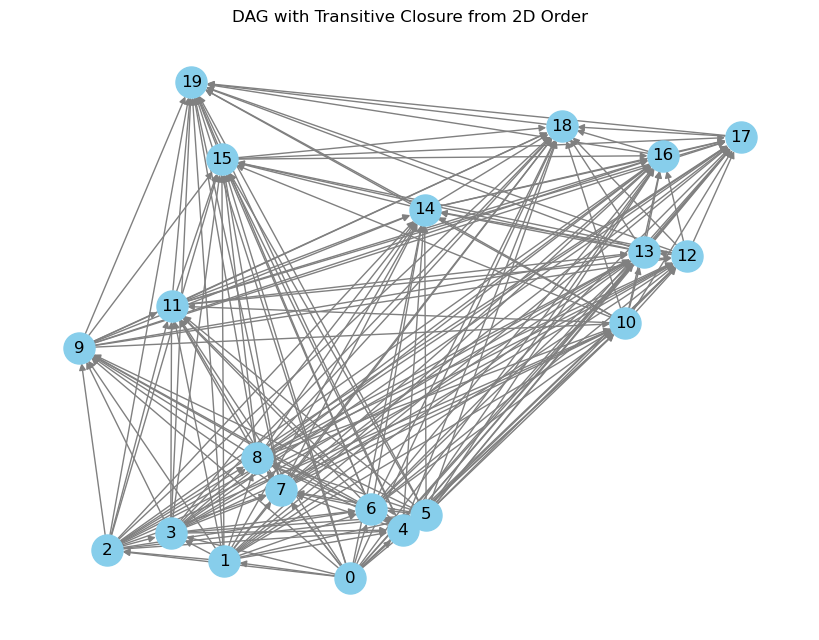

Structure Counts: {'3-chains': 1140, 'diamonds': 0}


In [36]:
# Example usage:
N = 20  # Number of nodes
dag, counts = generate_2d_order_dag_with_transitive_closure(N)
plot_dag(dag)
print("Structure Counts:", counts)


# The above approach uses Total ordering and will **never** produce a diamond
Below we use partial orders instead

In [89]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from itertools import combinations

def generate_dag_with_partial_order(N, box_size=1.0, layer_size=3):
    """
    Generates a DAG using a 2D order with a partial time order (small randomness in ranking),
    ensuring some nodes remain unordered and diamonds can form.

    Parameters:
        N (int): Number of nodes
        box_size (float): Size of the spatial coordinate domain
        layer_size (int): Approximate number of nodes per time layer

    Returns:
        G (networkx.DiGraph): The generated DAG with transitive closure
        counts (dict): Counts of 3-chains and diamonds
    """
    # Step 1: Generate random (x, t) coordinates
    x = np.random.uniform(0, box_size, N)  # Spatial coordinate
    t = np.random.uniform(0, box_size, N)  # Temporal coordinate

    # Step 2: Sort nodes into layers (not strictly by t, but approximately)
    indices = np.argsort(t)
    sorted_x = x[indices]
    sorted_t = t[indices]

    # Step 3: Create approximate layers (allow small overlap to prevent strict ordering)
    layers = {i: sorted_t[i] // (box_size / (N // layer_size)) for i in range(N)}
    print(layers)

    G = nx.DiGraph()
    
    # Step 4: Create edges based on spatial and partial temporal order
    for i in range(N):
        G.add_node(i, pos=(sorted_x[i], sorted_t[i]))
        for j in range(i + 1, N):
            if layers[i] < layers[j]:  # Enforce acyclicity while allowing some independence
                G.add_edge(i, j)

    # Step 5: Compute transitive closure
    G_tc = nx.transitive_closure(G)

    # Step 6: Count 3-chains and diamonds
    num_3chains = 0
    num_diamonds = 0

    for i in G_tc.nodes:
        successors = list(G_tc.successors(i))
        # for j in successors:
        #     num_3chains += len(set(G_tc.successors(j)))
        #     print(i, j, [k for k in G_tc.successors(j)])
        for j, k in combinations(successors, 2):  # Check pairs of successors
            if not G_tc.has_edge(j, k) and not G_tc.has_edge(k, j):  # Ensure j and k are independent
                common_successors = set(G_tc.successors(j)) & set(G_tc.successors(k))
                num_diamonds += len(common_successors)  # Each shared successor forms a diamond
            for m in G_tc.successors(j):  
                #print(i , j, m)
                num_3chains += 1

    return G_tc, {"3-chains": num_3chains, "diamonds": num_diamonds}

def plot_dag(G):
    """
    Plots the DAG using its 2D embedding.
    """
    pos = nx.get_node_attributes(G, 'pos')
    plt.figure(figsize=(8, 6))
    nx.draw(G, pos, with_labels=True, node_size=500, node_color='skyblue', edge_color='gray', arrows=True)
    plt.xlabel("Spatial coordinate (x)")
    plt.ylabel("Temporal coordinate (t)")
    plt.title("DAG with Partial Ordering")
    plt.show()


{0: 0.0, 1: 0.0, 2: 1.0, 3: 2.0, 4: 2.0, 5: 3.0, 6: 3.0, 7: 4.0, 8: 4.0, 9: 4.0}


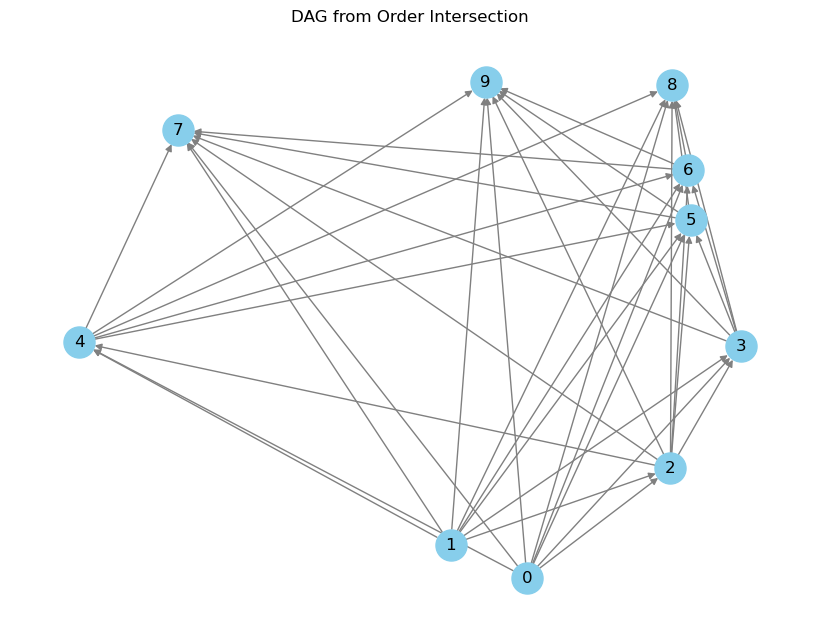

Structure Counts: {'3-chains': 368, 'diamonds': 30}


In [99]:
# Example usage:
N = 10  # Number of nodes
dag, counts = generate_dag_with_partial_order(N, layer_size=2)
plot_dag(dag)
print("Structure Counts:", counts)

## use 2 linear orderings below:

In [123]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from itertools import combinations

def generate_dag_from_order_intersection(N):
    """
    Generates a DAG from the intersection of two random linear orders.

    Parameters:
        N (int): Number of nodes

    Returns:
        G_tc (networkx.DiGraph): The DAG with explicit transitive closure
        counts (dict): Counts of 3-chains and diamonds
        h (list): List indicating if a vertex is above the line (1) or below (0)
    """
    # Step 1: Generate two independent linear orders
    order1 = np.random.permutation(N)  # Random ranking 1 (e.g., time)
    order2 = np.random.permutation(N)  # Random ranking 2 (e.g., hidden factor)

    rank1 = {node: rank for rank, node in enumerate(order1)}
    rank2 = {node: rank for rank, node in enumerate(order2)}

    G = nx.DiGraph()

    # Step 2: Construct edges based on intersection of both orders
    for i in range(N):
        G.add_node(i, pos=(rank1[i], rank2[i]))  # Store 2D rank as position

        for j in range(N):
            if rank1[i] < rank1[j] and rank2[i] < rank2[j]:  # Intersection rule
                G.add_edge(i, j)

    # Step 3: Compute transitive closure
    G_tc = nx.transitive_closure(G)

    # Step 4: Count 3-chains and diamonds
    num_3chains = 0
    num_diamonds = 0
    bh_links = 0
    
    maximal_nodes = set()
    maximal_but_one_nodes = set()
    
    for i in G_tc.nodes:
        if len(list(G_tc.successors(i))) == 0:
            maximal_nodes.add(i)
            print(i)
        if len(list(G_tc.successors(i))) == 1:
            maximal_but_one_nodes.add(i)

    for i in G_tc.nodes:
            
        successors = list(G_tc.successors(i))
        for j in successors:
            num_3chains += len(set(G_tc.successors(j)))
            
        for j, k in combinations(successors, 2):  # Check pairs of successors
            if not G_tc.has_edge(j, k) and not G_tc.has_edge(k, j):  # Ensure j and k are independent
                common_successors = set(G_tc.successors(j)) & set(G_tc.successors(k))
                num_diamonds += len(common_successors)  # Each shared successor forms a diamond

    # Step 5: Generate a random line and determine if vertices are above or below
    slope = np.random.uniform(-1, 1)
    intercept = np.random.uniform(0, N)
    h = []
    for i in range(N):
        x, y = rank1[i], rank2[i]
        if y > slope * x + intercept:
            h.append(1)
        else:
            h.append(0)
            
    for vertex in maximal_but_one_nodes:
        if h[vertex] == 0:
            successor = list(G_tc.successors(vertex))[0]
            if successor in maximal_nodes and h[successor] == 1:
                bh_links += 1
                
    # create an adjacency matrix:
    adj_matrix = nx.to_numpy_array(G_tc, nodelist=range(N))
    adj_matrix = np.array(adj_matrix)

    return G_tc, {"3-chains": num_3chains, "diamonds": num_diamonds, "bh-links": bh_links}, adj_matrix, h, slope, intercept

def plot_dag(G, slope, intercept):
    """
    Plots the DAG using its 2D ranking positions and a random line.
    """
    pos = nx.get_node_attributes(G, 'pos')
    plt.figure(figsize=(8, 6))
    nx.draw(G, pos, with_labels=True, node_size=500, node_color='skyblue', edge_color='gray', arrows=True)
    
    # Plot the random line
    x_vals = np.array(plt.gca().get_xlim())
    y_vals = slope * x_vals + intercept
    plt.plot(x_vals, y_vals, '--', color='red')
    
    plt.xlabel("Rank in Order 1")
    plt.ylabel("Rank in Order 2")
    plt.title("DAG from Order Intersection with Random Line")
    plt.show()


9
1
7
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 1. 1. 0. 1. 1. 1. 0.]
 [0. 1. 0. 0. 1. 1. 0. 1. 1. 1. 0.]
 [0. 1. 0. 0. 0. 0. 0. 1. 1. 1. 0.]
 [0. 1. 0. 0. 0. 0. 0. 1. 0. 1. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 1. 1. 1. 0. 1. 1. 1. 0.]]


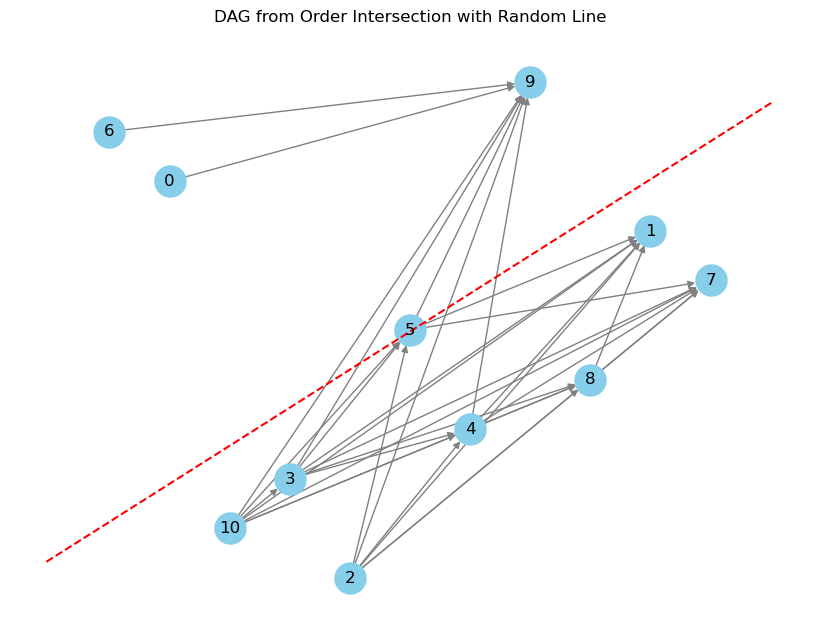

Structure Counts: {'3-chains': 35, 'diamonds': 15, 'bh-links': 0}
h: [1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0]


In [127]:
# Example usage:
N = 11  # Number of nodes
dag, counts, adj_mat, h, slope, intercept = generate_dag_from_order_intersection(N)
# retrieve the adjacency matrix from the graph
dag_adj = nx.to_numpy_array(dag, nodelist=range(N))
print(dag_adj)

plot_dag(dag, slope, intercept)
print("Structure Counts:", counts)
print("h:", h)

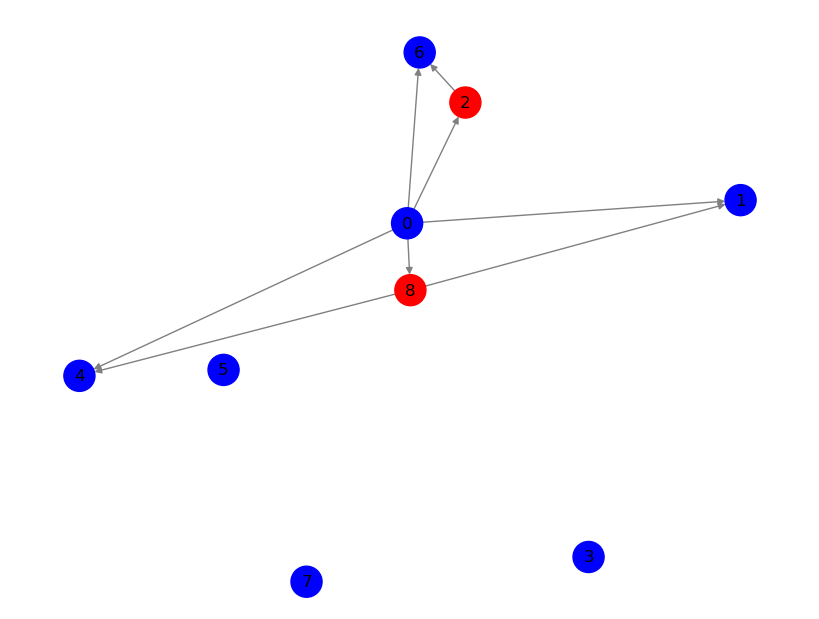

In [124]:
xs = [1, 0, 1, 0, 0, 1, 0, 0, 0]
ys = [0, 1, 1, 1, 1, 1, 0, 0, 0]

# color the nodes in the graph red if x[i] or green if y[i]:
colors = ['red' if x and y else 'blue' for (x, y) in zip(xs, ys)]

# plot the graph with the node colors
plt.figure(figsize=(8, 6))
nx.draw(dag, with_labels=True, node_size=500, node_color=colors, edge_color='gray', arrows=True)

